In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
import math
from sklearn.metrics import confusion_matrix
from torchvision.datasets import MNIST
import seaborn as sns
import torch
import torchvision.transforms as transforms
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split 

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [3]:
class RowTokenizer(nn.Module):

    def __init__(self, img_size=(32, 32), n_channels=1, d_model=64):
        super().__init__()
        H, W = img_size
        # Chiếu mỗi hàng (W * n_channels) sang d_model
        self.proj = nn.Linear(W * n_channels, d_model)

    def forward(self, x):
        # x: (B, C, H, W) -> (B, H, W * C)
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1).reshape(B, H, W * C)
        x = self.proj(x)  # (B, H, d_model)
        return x

In [4]:
class PyTorchMultiHeadAttention(nn.Module):

    def __init__(self, d_model, n_heads):
        super().__init__()
        self.mha = nn.MultiheadAttention(
            embed_dim=d_model, num_heads=n_heads, batch_first=True
        )

    def forward(self, x):
        out, _ = self.mha(x, x, x)
        return out

In [5]:
class TransformerEncoderBlockPyTorch(nn.Module):
    def __init__(self, d_model, n_heads, r_mlp=4):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.mha = PyTorchMultiHeadAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_model * r_mlp),
            nn.GELU(),
            nn.Linear(d_model * r_mlp, d_model)
        )

    def forward(self, x):
        x = x + self.mha(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

In [6]:
d_model, n_classes, img_size, patch_size = 64, 10, (32, 32), (16, 16)
n_channels, n_heads, n_layers, batch_size, epochs, alpha = (
    1,
    8,
    6,
    64,
    10,
    0.001,
)

In [7]:
print("Tải dữ liệu và tính toán thông số chuẩn hóa...")

# Bước 1: Tải tập dữ liệu thô để tính mean và std chính xác (đã chia 255)
raw_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
raw_data_normalized = raw_train.data.float() / 255.0

pixel_mean = raw_data_normalized.mean().item()
pixel_std = raw_data_normalized.std().item()

print(f"Pixel Mean tính toán động: {pixel_mean:.4f}")
print(f"Pixel Std tính toán động: {pixel_std:.4f}")

# Bước 2: Tạo bộ transform động chuẩn hoá dữ liệu dựa trên mean và std tính toán
dynamic_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((pixel_mean,), (pixel_std,))
])

# Bước 3: Khởi tạo Dataset với transform chuẩn
train_dataset_original = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=dynamic_transform
)
test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=dynamic_transform
)
train_size = int(0.9 * len(train_dataset_original))  # 54.000 mẫu
val_size = len(train_dataset_original) - train_size   # 6.000 mẫu
# Bước 4: Tạo DataLoader
train_dataset, val_dataset = random_split(train_dataset_original, [train_size, val_size])

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

Tải dữ liệu và tính toán thông số chuẩn hóa...
Pixel Mean tính toán động: 0.1307
Pixel Std tính toán động: 0.3081


In [8]:
class VisionTransformer(nn.Module):

    def __init__(
        self,
        d_model,
        n_classes,
        img_size,
        n_channels,
        n_heads,
        n_layers,
    ):
        super().__init__()
        H, W = img_size
        self.n_rows = H
        # Tổng số token = số hàng (H) + 1 token CLS
        self.max_seq_length = self.n_rows + 1

        self.row_embedding = RowTokenizer(img_size, n_channels, d_model)

        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))
        # Positional encoding cho toàn bộ chuỗi (CLS token + H hàng)
        self.pos_embedding = nn.Parameter(
            torch.randn(1, self.max_seq_length, d_model)
        )

        self.transformer_encoder = nn.Sequential(
            *[TransformerEncoderBlockPyTorch(d_model, n_heads) for _ in range(n_layers)]
        )
        self.classifier = nn.Linear(d_model, n_classes)

    def forward(self, images):
        B = images.shape[0]

        # 1. Biến đổi ảnh thành danh sách các row tokens: (B, H, d_model)
        x = self.row_embedding(images)

        # 2. Thêm CLS Token vào đầu chuỗi: (B, 1 + H, d_model)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        # 3. Cộng Positional Embedding chuẩn cho toàn bộ chuỗi
        x = x + self.pos_embedding

        # 4. Đưa qua Transformer Encoder & Classifier
        x = self.transformer_encoder(x)
        return self.classifier(x[:, 0])  # Lấy đại diện từ CLS token

In [9]:
transformer = VisionTransformer(
    d_model=d_model,
    n_classes=n_classes,
    img_size=img_size,
    n_channels=n_channels,
    n_heads=n_heads,
    n_layers=n_layers,
).to(device)

# Bộ tối ưu & Hàm mất mát
optimizer = Adam(transformer.parameters(), lr=alpha)
criterion = nn.CrossEntropyLoss()

In [10]:
# Khởi tạo history 
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [], 
    "val_accuracy": [],
    "confusion_matrix": [],
}

# VÒNG LẶP HUẤN LUYỆN & ĐÁNH GIÁ
for epoch in range(epochs):
  # --- Train Phase ---
  transformer.train()
  running_train_loss = 0.0
  train_correct = 0
  train_total = 0

  for inputs, labels in train_loader:
    inputs, labels = inputs.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = transformer(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_train_loss += loss.item()
    _, predicted = torch.max(outputs.data, 1)
    train_total += labels.size(0)
    train_correct += (predicted == labels).sum().item()

  epoch_train_loss = running_train_loss / len(train_loader)
  epoch_train_acc = 100 * train_correct / train_total

  history["train_loss"].append(epoch_train_loss)
  history["train_accuracy"].append(epoch_train_acc)  

  # --- Validation Phase ---
  transformer.eval()
  running_val_loss = 0.0
  correct, total = 0, 0
  all_preds, all_labels = [], []

  with torch.no_grad():
    for inputs, labels in val_loader:
      inputs, labels = inputs.to(device), labels.to(device)
      outputs = transformer(inputs)
      loss = criterion(outputs, labels)
      running_val_loss += loss.item()

      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

      # Thu thập nhãn cho epoch cuối để tính Confusion Matrix
      if epoch == epochs - 1:
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

  epoch_val_loss = running_val_loss / len(val_loader)
  epoch_accuracy = 100 * correct / total

  history["val_loss"].append(epoch_val_loss)
  history["val_accuracy"].append(epoch_accuracy)

  print(
      f"Epoch {epoch+1}/{epochs} | "
      f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% |"
      f" Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_accuracy:.2f}%"
  )

# Compute and store the confusion matrix after the final epoch
# Tính Confusion Matrix cho epoch cuối
cm = confusion_matrix(all_labels, all_preds)
history["confusion_matrix"] = cm.tolist()

Epoch 1/10 | Train Loss: 0.2555 - Train Acc: 91.64% | Val Loss: 0.1080 - Val Acc: 96.72%
Epoch 2/10 | Train Loss: 0.0873 - Train Acc: 97.25% | Val Loss: 0.0984 - Val Acc: 97.08%
Epoch 3/10 | Train Loss: 0.0649 - Train Acc: 97.92% | Val Loss: 0.0631 - Val Acc: 98.27%
Epoch 4/10 | Train Loss: 0.0521 - Train Acc: 98.31% | Val Loss: 0.0816 - Val Acc: 97.72%
Epoch 5/10 | Train Loss: 0.0457 - Train Acc: 98.50% | Val Loss: 0.0625 - Val Acc: 98.32%
Epoch 6/10 | Train Loss: 0.0436 - Train Acc: 98.55% | Val Loss: 0.0683 - Val Acc: 98.15%
Epoch 7/10 | Train Loss: 0.0371 - Train Acc: 98.77% | Val Loss: 0.0748 - Val Acc: 97.90%
Epoch 8/10 | Train Loss: 0.0346 - Train Acc: 98.91% | Val Loss: 0.0860 - Val Acc: 97.65%
Epoch 9/10 | Train Loss: 0.0281 - Train Acc: 99.11% | Val Loss: 0.0778 - Val Acc: 97.97%
Epoch 10/10 | Train Loss: 0.0312 - Train Acc: 98.97% | Val Loss: 0.0838 - Val Acc: 97.82%


In [12]:
# Đưa mô hình về chế độ evaluation (tắt dropout, cố định batchnorm nếu có)
transformer.eval()

test_loss = 0.0
correct = 0
total = 0
all_preds = []
all_labels = []

# Tắt tính toán gradient để tiết kiệm bộ nhớ và tăng tốc độ
with torch.no_grad():
  for inputs, labels in test_loader:
    inputs, labels = inputs.to(device), labels.to(device)

    # Forward pass
    outputs = transformer(inputs)
    loss = criterion(outputs, labels)

    test_loss += loss.item()

    # Thống kê số lượng dự đoán đúng
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

    # Lưu lại kết quả dự đoán và nhãn thực tế để vẽ Confusion Matrix
    all_preds.extend(predicted.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())

# Tính toán Loss và Accuracy trung bình trên toàn bộ tập test
avg_test_loss = test_loss / len(test_loader)
test_accuracy = 100 * correct / total

print(f"=== Kết quả đánh giá trên test loader ===")
print(f"Test Loss     : {avg_test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.2f}%")

=== Kết quả đánh giá trên test loader ===
Test Loss     : 0.0481
Test Accuracy : 98.51%



Đã lưu kết quả huấn luyện vào file: msa_pytorch_Row_training_results.json


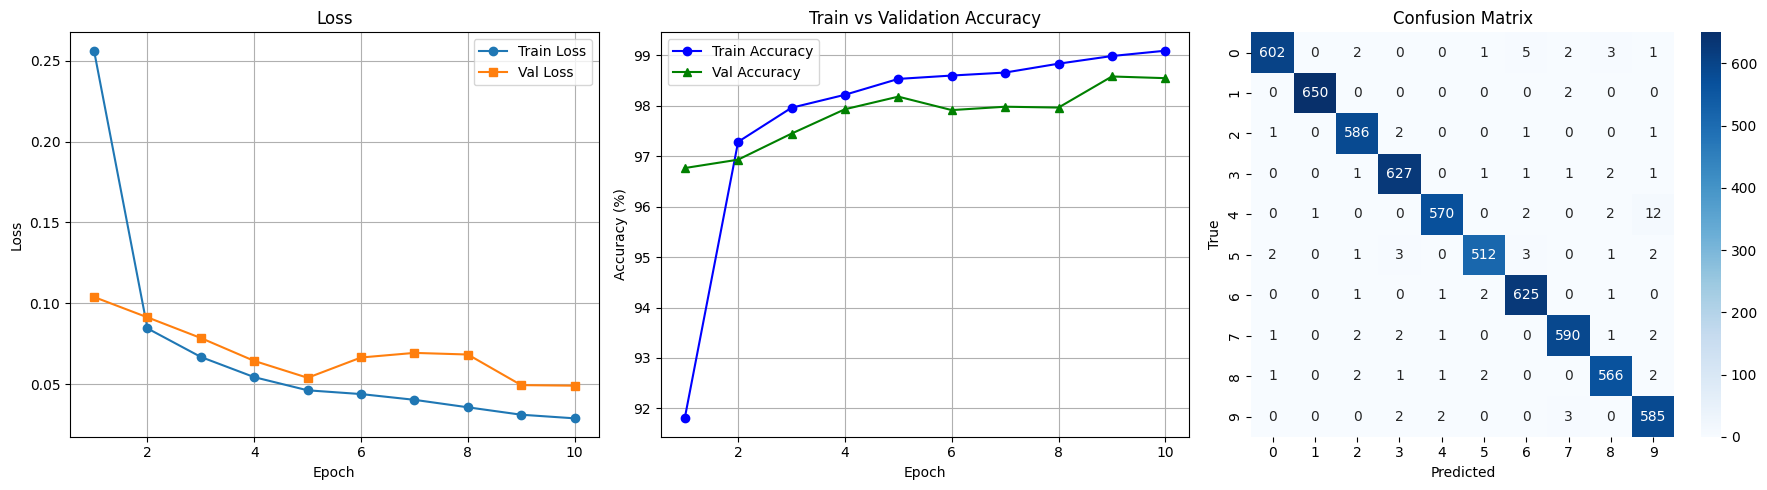

In [13]:

# --- LƯU THÔNG TIN VÀO FILE JSON ---
json_path = "msa_pytorch_Row_training_results.json"
with open(json_path, "w") as f:
    json.dump(history, f, indent=4)
print(f"\nĐã lưu kết quả huấn luyện vào file: {json_path}")

# --- VẼ ĐỒ THỊ BIỂU DIỄN ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Đồ thị 1: Training & Validation Loss
axes[0].plot(
    range(1, epochs + 1), history["train_loss"], label="Train Loss", marker="o"
)
axes[0].plot(
    range(1, epochs + 1), history["val_loss"], label="Val Loss", marker="s"
)
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Đồ thị 2: Train Accuracy & Validation Accuracy (Vẽ chung một đồ thị)
axes[1].plot(
    range(1, epochs + 1),
    history["train_accuracy"],
    color="blue",
    marker="o",
    label="Train Accuracy",
)
axes[1].plot(
    range(1, epochs + 1),
    history["val_accuracy"],
    color="green",
    marker="^",
    label="Val Accuracy",
)
axes[1].set_title("Train vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

# Đồ thị 3: Confusion Matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[2],
    xticklabels=range(10),
    yticklabels=range(10),
)
axes[2].set_title("Confusion Matrix")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("True")

plt.tight_layout()
plt.savefig("msa_Row_pytorch_training_metrics.png")
plt.show()